# Default classifier comparison

CM2604 Coursework 1, Part 01. This initial comparison evaluates the three required classifiers against the majority-class baseline using training cross-validation. No hyperparameter tuning, final model selection or held-out test evaluation is performed.

## How the models work

| Model | Prediction method | Starting configuration |
|---|---|---|
| KNN | Finds the five nearest training customers in the transformed feature space and uses their labels to vote. Churn probability is the fraction of those neighbours labelled Yes. | 5 neighbours, uniform weights, Euclidean distance; scaled numeric predictors |
| Logistic regression | Learns a weighted sum of the predictors and converts it to a churn probability using the sigmoid function, p = 1 / (1 + exp(-z)). Regularisation limits coefficient size. | C=1, lbfgs solver, max_iter=2000, no class weights; scaled numeric predictors |
| Random forest | Fits 100 trees on bootstrap samples, considering random feature subsets at splits, then averages their class probabilities. | 100 trees, unrestricted depth, seed 42; unscaled numeric predictors |

These descriptions follow scikit-learn developers (n.d.a, n.d.b, n.d.c). KNN depends on the distance representation; logistic regression uses a linear score before the sigmoid; unrestricted trees can learn detailed training patterns. Those properties motivate later tuning, without changing this release's fixed starting settings.

## Shared experimental method

Use the original validated CSV and the fixed stratified 80/20 split with seed 42. Only the 5,634 training rows enter the five shuffled stratified folds, also seeded 42. Each fold fits its own complete pipeline: numeric conversion and median imputation; optional numeric scaling; categorical mode imputation and one-hot encoding. No preprocessing statistics are learned from validation or held-out rows.

Churn Yes=1 is the positive class. Prediction uses each classifier's normal 0.5 binary decision boundary; ties favour No. Scores include F1, precision, recall, accuracy, balanced accuracy, ROC-AUC and average precision. Fold means have equal weight; standard deviations use ddof=0. Fit times include preprocessing. Timing varies between runs. The baseline is rerun on the same folds for a directly comparable reference.

In [1]:
from pathlib import Path
import sys
import warnings
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data.py").is_file():
    raise RuntimeError("Run from the repository root or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.exceptions import ConvergenceWarning
from src.data import load_data, split_data, NUMERIC_COLUMNS, CATEGORIES
from src.train import evaluate_defaults, export_default_comparison, SCORING

X_train, X_test, y_train, y_test = split_data(load_data())
held_out_indices = set(X_test.index)
assert len(X_train) == 5634 and len(X_test) == 1409
assert not set(X_train.index) & held_out_indices
# Keep only index membership for separation audits, not held-out features/labels.
del X_test, y_test
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    results = evaluate_defaults(X_train, y_train)
folds, summary = export_default_comparison(results)
print("Completed four models, five folds each, using training data only.")

Completed four models, five folds each, using training data only.


## Fold and prediction checks

The audit checks that models use identical fold memberships, that all training rows receive one validation prediction per model and that no held-out row enters any fold. It also checks the fitted medians, category vocabularies and numeric scaling against the corresponding training subset. Prediction probabilities must be finite and sum to one. Confusion-count formulas independently check the threshold-based metrics.

In [2]:
reference = results["baseline"]["indices"]
audit_rows = []
for name, result in results.items():
    seen = []
    for number, (model, fit_positions, val_positions) in enumerate(zip(
            result["estimator"], result["indices"]["train"], result["indices"]["test"]), 1):
        np.testing.assert_array_equal(fit_positions, reference["train"][number-1])
        np.testing.assert_array_equal(val_positions, reference["test"][number-1])
        fit_data = X_train.iloc[fit_positions]
        val_data = X_train.iloc[val_positions]
        assert not set(fit_data.index) & set(val_data.index)
        assert not (set(fit_data.index) | set(val_data.index)) & held_out_indices
        seen.extend(val_data.index)
        prep = model["preprocess"]
        numeric = prep.named_transformers_["numeric"]
        np.testing.assert_allclose(numeric["impute"].statistics_, fit_data[NUMERIC_COLUMNS].median())
        if "scale" in numeric.named_steps:
            imputed = fit_data[NUMERIC_COLUMNS].fillna(fit_data[NUMERIC_COLUMNS].median())
            np.testing.assert_allclose(numeric["scale"].mean_, imputed.mean())
        categories = prep.named_transformers_["categorical"]["encode"].categories_
        for column, vocabulary in zip(CATEGORIES, categories):
            assert set(vocabulary) == set(fit_data[column].dropna())
        probabilities = model.predict_proba(val_data)
        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()
        np.testing.assert_allclose(probabilities.sum(axis=1), 1)
        predictions = model.predict(val_data)
        np.testing.assert_array_equal(predictions, (probabilities[:, 1] > 0.5).astype(int))
        labels = y_train.iloc[val_positions].to_numpy()
        tp = int(((predictions == 1) & (labels == 1)).sum())
        tn = int(((predictions == 0) & (labels == 0)).sum())
        fp = int(((predictions == 1) & (labels == 0)).sum())
        fn = int(((predictions == 0) & (labels == 1)).sum())
        expected = {"accuracy": (tp+tn)/len(labels),
                    "precision": tp/(tp+fp) if tp+fp else 0,
                    "recall": tp/(tp+fn), "f1": 2*tp/(2*tp+fp+fn),
                    "balanced_accuracy": (tp/(tp+fn)+tn/(tn+fp))/2}
        actual = folds.loc[(folds.model == name) & (folds.fold == number)].iloc[0]
        for metric, value in expected.items():
            np.testing.assert_allclose(actual[metric], value)
        if name == "logistic_regression":
            assert model["model"].n_iter_.max() < 2000
        audit_rows.append({"model": name, "fold": number,
                           "training_rows": len(fit_data), "validation_rows": len(val_data),
                           "held_out_overlap": 0, "checks": "passed"})
    assert len(seen) == len(X_train) and set(seen) == set(X_train.index)
audit = pd.DataFrame(audit_rows)
display(audit)

,model,fold,training_rows,validation_rows,held_out_overlap,checks
0,baseline,1,4507,1127,0,passed
1,baseline,2,4507,1127,0,passed
2,baseline,3,4507,1127,0,passed
3,baseline,4,4507,1127,0,passed
4,baseline,5,4508,1126,0,passed
5,knn,1,4507,1127,0,passed
6,knn,2,4507,1127,0,passed
7,knn,3,4507,1127,0,passed
8,knn,4,4507,1127,0,passed
9,knn,5,4508,1126,0,passed


## Comparable results

Each table row reports the mean and population standard deviation across the same five validation folds. A higher validation score here does not establish the final model: tuning and final selection remain later stages.

In [3]:
metric_rows = summary[summary.metric.isin(SCORING)].copy()
metric_rows["mean +/- std"] = metric_rows.apply(lambda row: f"{row['mean']:.4f} +/- {row['std']:.4f}", axis=1)
comparison = metric_rows.pivot(index="model", columns="metric", values="mean +/- std")
display(comparison[list(SCORING)])
display(summary[summary.metric.isin(["fit_seconds", "score_seconds"])].pivot(index="model", columns="metric", values="mean"))
means = metric_rows.pivot(index="model", columns="metric", values="mean")
leader = means["f1"].idxmax()
display(Markdown(f"Among these default settings, **{leader.replace('_', ' ')}** has the highest mean churn F1 "
                 f"({means.loc[leader, 'f1']:.4f}). Its mean churn recall is {means.loc[leader, 'recall']:.4f} "
                 f"and mean accuracy is {means.loc[leader, 'accuracy']:.4f}. "
                 "The baseline has zero churn F1 and recall. These observations concern training cross-validation only; "
                 "no final configuration is selected here."))

metric,f1,precision,recall,accuracy,balanced_accuracy,roc_auc,average_precision
model,,,,,,,
baseline,0.0000 +/- 0.0000,0.0000 +/- 0.0000,0.0000 +/- 0.0000,0.7346 +/- 0.0001,0.5000 +/- 0.0000,0.5000 +/- 0.0000,0.2654 +/- 0.0001
knn,0.5457 +/- 0.0136,0.5615 +/- 0.0098,0.5311 +/- 0.0199,0.7655 +/- 0.0051,0.6907 +/- 0.0091,0.7822 +/- 0.0050,0.5070 +/- 0.0123
logistic_regression,0.5930 +/- 0.0298,0.6547 +/- 0.0280,0.5431 +/- 0.0411,0.8026 +/- 0.0120,0.7198 +/- 0.0199,0.8461 +/- 0.0125,0.6614 +/- 0.0193
random_forest,0.5385 +/- 0.0204,0.6232 +/- 0.0267,0.4749 +/- 0.0258,0.7842 +/- 0.0093,0.6854 +/- 0.0124,0.8178 +/- 0.0112,0.6089 +/- 0.0275


metric,fit_seconds,score_seconds
model,,
baseline,0.047129,0.047501
knn,0.055427,0.075565
logistic_regression,0.062416,0.046971
random_forest,0.307423,0.078715


Among these default settings, **logistic regression** has the highest mean churn F1 (0.5930). Its mean churn recall is 0.5431 and mean accuracy is 0.8026. The baseline has zero churn F1 and recall. These observations concern training cross-validation only; no final configuration is selected here.

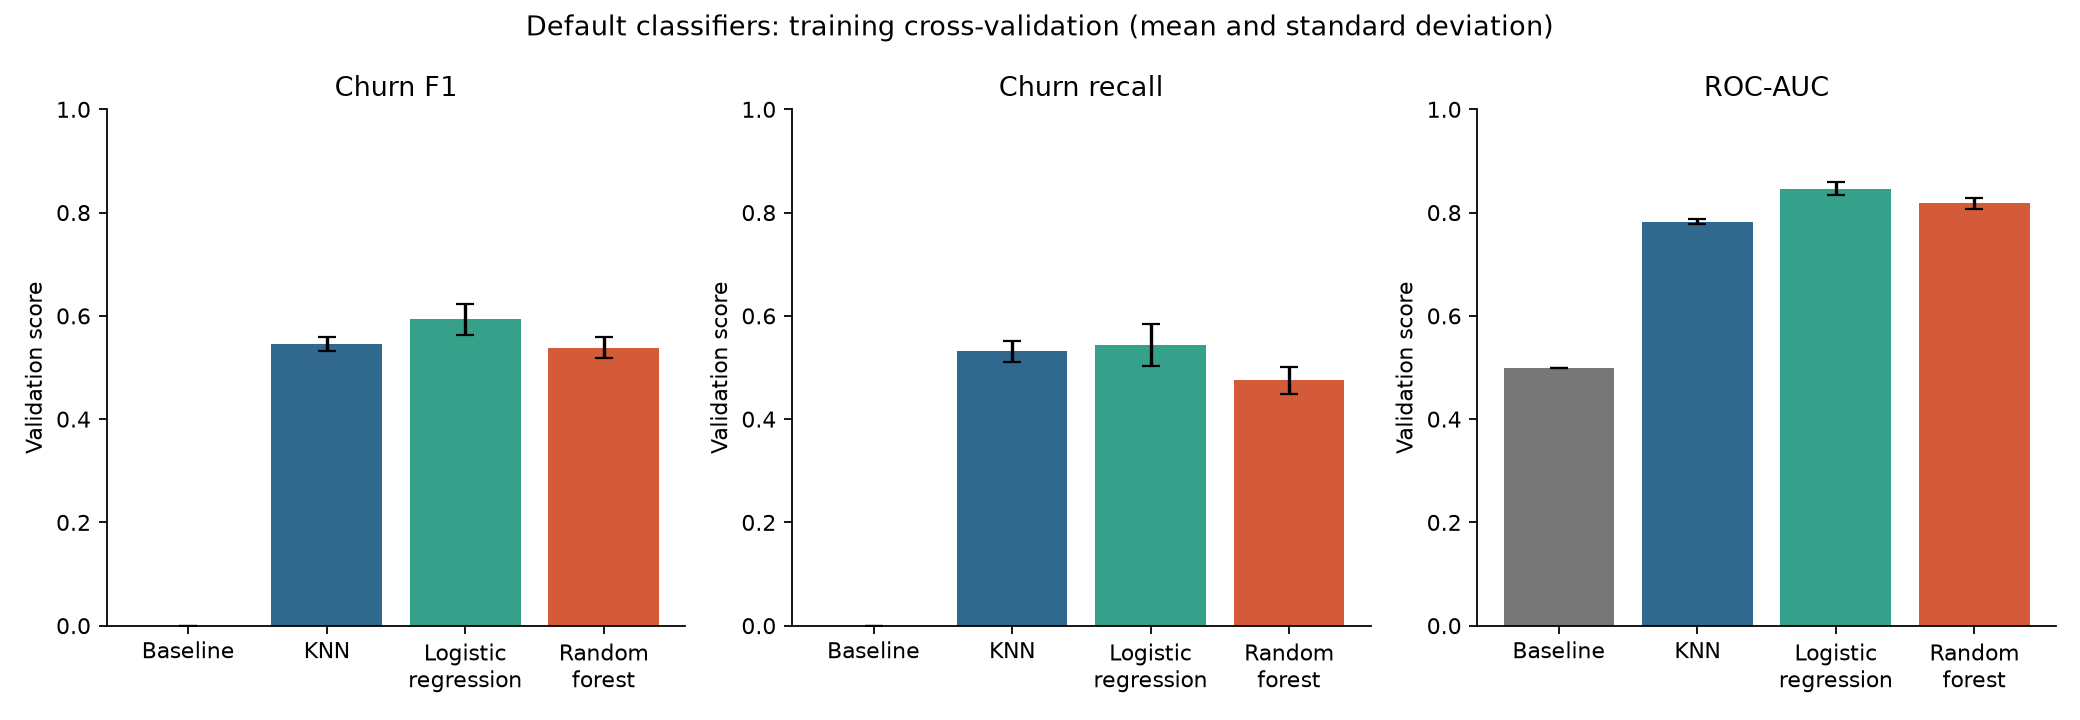

In [4]:
order = ["baseline", "knn", "logistic_regression", "random_forest"]
labels = ["Baseline", "KNN", "Logistic\nregression", "Random\nforest"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, metric, title in zip(axes, ["f1", "recall", "roc_auc"], ["Churn F1", "Churn recall", "ROC-AUC"]):
    rows = metric_rows[metric_rows.metric.eq(metric)].set_index("model").loc[order]
    ax.bar(labels, rows["mean"], yerr=rows["std"], capsize=4,
           color=["#777777", "#31688e", "#35a18b", "#d45b39"])
    ax.set(title=title, ylabel="Validation score", ylim=(0, 1))
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Default classifiers: training cross-validation (mean and standard deviation)")
fig.tight_layout()
figure_path = ROOT / "outputs" / "figures" / "default_model_metrics.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, metadata={"Software": "Matplotlib"})
plt.close(fig)
display(Image(filename=str(figure_path)))

## Saved outputs and limits

The run exports `default_cv_folds.csv`, `default_cv_summary.csv` and `default_model_configuration.json` under `outputs/tables/`, plus `default_model_metrics.png` under `outputs/figures/`. The configuration records the estimator parameters and software version. Existing exploration and Release 3 baseline outputs are preserved.

These are untuned comparisons at the fixed decision boundary. Fold standard deviations describe variation across this split's folds; they are not confidence intervals or proof that a small difference is meaningful. The held-out partition has not been evaluated. Hyperparameter searches, selection of a final configuration, final test metrics and the report are future work.

In [5]:
TABLES = ROOT / "outputs" / "tables"
pd.testing.assert_frame_equal(pd.read_csv(TABLES / "default_cv_folds.csv"), folds, check_dtype=False)
pd.testing.assert_frame_equal(pd.read_csv(TABLES / "default_cv_summary.csv"), summary, check_dtype=False)
assert len(folds) == 20 and len(summary) == 36
assert set(results) == {"baseline", "knn", "logistic_regression", "random_forest"}
print("All shared-fold, training-only preprocessing, probability, metric and export checks passed.")

All shared-fold, training-only preprocessing, probability, metric and export checks passed.


## References

scikit-learn developers (n.d.a) *KNeighborsClassifier*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

scikit-learn developers (n.d.b) *LogisticRegression*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers (n.d.c) *Random forests and other randomized tree ensembles*. Available at: https://scikit-learn.org/stable/modules/ensemble.html#forest

Documentation checked 28 October 2026. Dataset source and placement instructions are in the repository README.